# 05 · Contrastes planejados e sensibilidade a choques de categoria × semana

Este notebook reúne duas análises secundárias do projeto, as duas motivadas pelos resultados dos notebooks 03 e 04. A primeira examina se a associação entre desconto e vendas difere entre segmentos de loja, entre marca de fabricante e marca própria e entre categorias, por meio de três contrastes planejados, com correção de Holm sobre essa família fixa de três testes. A segunda compara o F3 do notebook 03 com uma versão que acrescenta um intercepto aleatório de categoria × semana, como sensibilidade motivada pelo diagnóstico residual do notebook 03.

Este notebook **não ajusta modelos**: os ajustes foram feitos por scripts (`scripts/fit_contrasts.py` e `scripts/fit_catweek_sensitivity.py`) e gravados em `outputs/runs`. O notebook apenas lê essas duas execuções, o que torna as versões em português e em inglês idênticas em resultados. Somente as 104 semanas de treino (semanas 0 a 103) entram nos cálculos, e as estimativas são associações condicionais em semanas com transações registradas, e não efeitos causais. A especificação oficial do C0 e o ranking preditivo gravado no protocolo P1 permanecem como foram registrados.

*Dados: dunnhumby Source Files – Breakfast at the Frat.*

In [1]:
LANG = "pt"

In [2]:
import warnings

import pandas as pd
from IPython.display import display

from retail_multilevel import viz
from retail_multilevel.i18n import contrast_label, format_p, level_label, localize_columns, t
from retail_multilevel.runs import load_run

warnings.filterwarnings("ignore", category=FutureWarning)
viz.use_retina()
pd.set_option("display.width", 140)
pd.set_option("display.max_colwidth", None)
pd.set_option("display.float_format", "{:,.4f}".format)
contrasts = load_run("p2_contrasts", "20261124-220904-eb35f45e")
catweek = load_run("p2_catweek", "20261124-220500-f7c26a70")
print(t("data_credit", LANG))
stored = {"contrasts": contrasts, "catweek": catweek}
display(pd.DataFrame({k: {"run_id": r.run_id, "finished_at": r.metadata["finished_at"]} for k, r in stored.items()}).T)

MODELS = {"F3_ref": t("model_f3_ref", LANG), "F3_catweek": t("model_f3_catweek", LANG)}
GROUPS = {"CATWEEK": t("group_catweek", LANG)}


def localized(df):
    out = df.copy()
    if "test" in out:
        for col in ("level", "reference"):
            if col in out:
                out[col] = [level_label(a, b, LANG) for a, b in zip(out["test"], out[col], strict=True)]
        out["test"] = [contrast_label(x, LANG) for x in out["test"]]
    if "model" in out:
        out["model"] = out["model"].map(lambda x: MODELS.get(x, x))
    if "group" in out:
        out["group"] = out["group"].map(lambda x: GROUPS.get(x, viz.group_label(x, LANG)))
    if "term" in out:
        out["term"] = [viz.term_label(x, LANG) for x in out["term"]]
    return localize_columns(out, LANG)

Dados: dunnhumby Source Files – Breakfast at the Frat


,run_id,finished_at
contrasts,20261124-220904-eb35f45e,2026-11-24T22:09:20.929617
catweek,20261124-220500-f7c26a70,2026-11-24T22:09:34.923902


As duas execuções lidas estão identificadas acima (identificador e horário de término). Os identificadores são fixados no código, de modo que reexecutar o notebook lê sempre os mesmos artefatos.

## 1. A pergunta e o desenho dos contrastes

A pergunta é se a inclinação do log das unidades em relação ao log do desconto (`LOG_DISC`) é a mesma em todos os níveis de um moderador. Os moderadores são o segmento da loja (referência `MAINSTREAM`), o tipo de marca (referência: marca de fabricante) e a categoria (referência `BAG SNACKS`, a primeira em ordem alfabética). Para cada moderador foi ajustado um modelo próprio, por mínimos quadrados com efeitos fixos de par loja × produto e de semana, obtidos pela transformação *within* (Wooldridge, 2010). A resposta é `LOG_UNITS`, e os controles são `LOG_DISC`, `LOG_BASE_PRICE`, `FEATURE`, `DISPLAY` e `TPR_ONLY`, os mesmos da sensibilidade intrapar do notebook 03. O modelo com interação acrescenta `LOG_DISC` multiplicado pelo indicador de cada nível diferente da referência, e a versão restrita, com a mesma amostra e os mesmos controles, omite essas interações.

Um ponto de identificação merece registro. O segmento, o tipo de marca e a categoria são constantes dentro de cada par loja × produto, de modo que o efeito principal do moderador é absorvido pelo efeito fixo do par e não é estimado. A interação com `LOG_DISC` permanece identificada, porque o desconto varia ao longo das semanas dentro do par: a diferença de inclinação é estimada comparando, entre níveis, como as vendas de um mesmo par respondem às próprias variações de desconto.

Uma diferença de inclinação descreve a heterogeneidade condicional de uma associação entre grupos. Ela responde a uma pergunta distinta da que motivou o candidato C1 do protocolo P1 (notebook 04), no qual a elasticidade ao desconto varia aleatoriamente entre lojas e produtos (Gelman & Hill, 2007) e é avaliada pelo erro de previsão fora da amostra. Nenhum resultado deste notebook altera a seleção preditiva do P1 nem o ranking gravado nele.

## 2. As populações e o suporte por nível

A primeira questão operacional é quais linhas entram em cada teste. A tabela a seguir mostra, para cada moderador, as linhas do treino, as linhas usadas, os pares e as exclusões.

In [3]:
display(localized(contrasts.load_table("populations")))

,Teste,Linhas de treino,Linhas,Pares,Linhas excluídas,Motivo da exclusão
0,Segmento,347092,338033,3763,9059,SEG_AMBIGUOUS=9059; missing SEGMENT=0
1,Tipo de marca,347092,347092,3859,0,missing PRIVATE_LABEL=0
2,Categoria,347092,347092,3859,0,missing CATEGORY=0


O teste por segmento usa 338.033 linhas e 3.763 pares, depois da exclusão de 9.059 linhas das duas lojas de segmento ambíguo (4503 e 17627); não há segmento ausente. Os testes por tipo de marca e por categoria usam as 347.092 linhas e os 3.859 pares do treino, sem casos sem classificação. As referências de cada fator foram fixadas antes da inspeção das estimativas.

A segunda questão é se há variação de desconto dentro do par em cada nível, porque é ela que identifica a interação. A tabela seguinte mostra, por nível, as linhas, os pares, o desvio-padrão intrapar de `LOG_DISC` e o número de pares com variação de desconto.

In [4]:
display(localized(contrasts.load_table("support")))

,Teste,Nível,Linhas,Pares,DP intrapar de LOG_DISC,Pares com variação de desconto
0,Segmento,MAINSTREAM,190805,2078,0.1369,2058
1,Segmento,UPSCALE,70965,764,0.1303,761
2,Segmento,VALUE,76263,921,0.1391,887
3,Tipo de marca,Marca nacional,255828,2937,0.1296,2881
4,Tipo de marca,Marca própria,91264,922,0.1520,921
5,Categoria,BAG SNACKS,84270,889,0.1010,873
6,Categoria,COLD CEREAL,114480,1155,0.1281,1155
7,Categoria,FROZEN PIZZA,71242,827,0.1359,816
8,Categoria,ORAL HYGIENE PRODUCTS,77100,988,0.1749,958


Todos os níveis têm variação de desconto dentro do par. A proporção de pares com variação de `LOG_DISC` vai de 96,3% (VALUE, com 887 de 921 pares) a 100% (COLD CEREAL, com 1.155 de 1.155 pares), e o desvio-padrão intrapar do desconto vai de 0,101 (BAG SNACKS) a 0,175 (ORAL HYGIENE PRODUCTS). Há, portanto, variação de onde extrair cada inclinação, embora a distribuição dos descontos difira entre os níveis.

## 3. Os testes globais e a correção de Holm

Para cada moderador, a hipótese nula conjunta é que todas as diferenças de inclinação em relação à referência são zero. A estatística é um Wald conjunto das q interações, calculado com a matriz completa de covariância agrupada em duas vias, por par e por semana (Cameron et al., 2011). Como há 104 semanas, número menor que o de pares, a referência é uma F(q, 103), isto é, com `min(G_par, G_semana) − 1` graus de liberdade no denominador, uma convenção aproximada para o número de clusters da dimensão menor (Cameron & Miller, 2015). A estatística F é a de Wald dividida por q. A tabela mostra a estatística, o número de restrições, os graus de liberdade, a contagem de clusters e o valor-p bruto.

In [5]:
wald = contrasts.load_table("wald")
tests = wald[["test", "reference", "q", "W", "F", "df1", "df2", "G_pair", "G_week"]].assign(
    p_raw=[format_p(p) for p in wald["p_raw"]]
)
display(localized(tests))

,Teste,Referência,Restrições (q),Estatística de Wald,F = W / q,GL do numerador,GL do denominador,Clusters de par,Clusters de semana,Valor-p bruto
0,Segmento,MAINSTREAM,2,12.2484,6.1242,2,103,3763,104,0.0031
1,Tipo de marca,Marca nacional,1,30.2717,30.2717,1,103,3859,104,2.76e-07
2,Categoria,BAG SNACKS,3,111.0092,37.0031,3,103,3859,104,2.61e-16


O teste por segmento (q = 2) tem F = 6,12 e valor-p bruto de 0,0031; o de tipo de marca (q = 1), F = 30,27 e valor-p de 2,76e-07; o de categoria (q = 3), F = 37,00 e valor-p de 2,61e-16. A confiabilidade desses valores depende de diagnósticos do desenho e da covariância, apresentados a seguir: o posto da matriz de desenho, o número de condição do bloco q × q da covariância das interações e seu menor autovalor, e a indicação de que uma correção para semidefinição positiva foi necessária.

In [6]:
diagnostics = wald[
    ["test", "design_rank", "n_terms", "rank_deficient", "cond_number", "min_eig", "twoway_psd_fixed", "design_cond", "available"]
]
display(localized(diagnostics))

,Teste,Posto do desenho,Colunas do desenho,Posto deficiente,Número de condição do bloco q × q,Menor autovalor do bloco,Correção PSD aplicada,Número de condição do desenho,Disponível
0,Segmento,7,7,False,2.1801,0.0017,False,12.5665,True
1,Tipo de marca,6,6,False,1.0000,0.0081,False,13.0660,True
2,Categoria,8,8,False,5.9744,0.0043,False,46.0431,True


Os três desenhos têm posto completo (7, 6 e 8 colunas), nenhum precisou de correção para semidefinição positiva, e o bloco q × q da covariância tem número de condição de no máximo 6,0, com menor autovalor entre 0,0017 e 0,0081. Os três testes estão, portanto, disponíveis.

A correção de Holm é aplicada a uma família fixa de três testes globais, ao nível de 5% (Holm, 1979). Os valores-p brutos, em ordem crescente, são multiplicados por 3, 2 e 1, com imposição de monotonicidade. Se algum teste fosse indisponível, por perda de posto ou por covariância instável, a família continuaria com três posições, e o valor-p da posição indisponível entraria como 1 no ajuste, sendo exibido como indisponível. Aqui, nenhuma posição é indisponível.

In [7]:
holm = contrasts.load_table("holm")
holm_view = holm.assign(
    p_raw=[format_p(p) for p in holm["p_raw"]],
    p_holm=[format_p(p) if ok else t("p_unavailable", LANG) for p, ok in zip(holm["p_holm"], holm["available"], strict=True)],
)
display(localized(holm_view))

,Teste,Valor-p bruto,Valor-p ajustado (Holm),Rejeita a 5%,Disponível
0,Segmento,0.0031,0.0031,True,True
1,Tipo de marca,2.76e-07,5.51e-07,True,True
2,Categoria,2.61e-16,7.83e-16,True,True


Depois do ajuste, os valores-p são 0,0031 para segmento, 5,51e-07 para tipo de marca e 7,83e-16 para categoria, e os três testes rejeitam a hipótese nula global a 5%. O ajuste não altera a decisão de nenhum dos três testes, e o de segmento, o de menor evidência da família, mantém o valor-p bruto por ocupar a última posição da ordenação.

Dois cuidados acompanham essa leitura. O primeiro é que o agrupamento em duas vias acomoda a dependência dentro do par, como a correlação serial entre semanas do mesmo par, e os choques contemporâneos compartilhados entre pares na mesma semana. A dependência fora dessas dimensões, em especial choques comuns persistentes entre semanas, não é coberta, e por isso o teste é tratado como aproximado. O segundo é que a covariância em duas vias é bem maior que a agrupada só por par, como mostra a tabela abaixo para o coeficiente de `LOG_DISC` no modelo restrito: o erro-padrão em duas vias, cerca de 0,079, é cerca de 1,8 vez o agrupado por par, cerca de 0,044, de modo que uma inferência baseada apenas no agrupamento por par seria otimista.

In [8]:
coef = contrasts.load_table("coefficients")
restricted = coef[(coef["model"] == "restricted") & (coef["term"] == "LOG_DISC")]
display(localized(restricted.drop(columns=["model", "term"]).rename(columns={"estimate": "slope"})))

,Teste,Inclinação,EP por par,EP por semana,EP em duas vias
0,Segmento,-1.7017,0.0445,0.0732,0.0793
12,Tipo de marca,-1.7031,0.0437,0.0729,0.0788
23,Categoria,-1.7031,0.0437,0.0729,0.0788


## 4. As inclinações por nível

Dado que os testes globais rejeitam, a questão seguinte é descritiva: como são as inclinações do desconto em cada nível. Uma inclinação mais negativa indica uma resposta maior das unidades a uma mesma variação do desconto. A tabela mostra, por nível, a inclinação estimada, seus erros-padrão, o intervalo de 95%, a diferença em relação à referência e o intervalo dessa diferença. Todos os intervalos são pontuais, calculados com o erro-padrão em duas vias, sem ajuste para multiplicidade. Para esta entrega, a inferência se encerra na família planejada de três testes, e as diferenças por nível são apresentadas de forma descritiva, sem uma bateria de comparações par a par.

,Teste,Nível,Nível de referência,Inclinação,EP por par,EP por semana,EP em duas vias,Inferior 95% (pontual),Superior 95% (pontual),Diferença vs. referência,EP da diferença,"Diferença, inferior 95%","Diferença, superior 95%"
0,Segmento,MAINSTREAM,True,-1.7458,0.0541,0.0779,0.0856,-1.9155,-1.5761,0.0000,0.0000,0.0000,0.0000
1,Segmento,UPSCALE,False,-1.5795,0.0453,0.0678,0.0766,-1.7315,-1.4276,0.1663,0.0475,0.0720,0.2606
2,Segmento,VALUE,False,-1.6857,0.0561,0.0745,0.0886,-1.8613,-1.5100,0.0601,0.0565,-0.0518,0.1721
3,Tipo de marca,Marca nacional,True,-1.9058,0.0440,0.0818,0.0899,-2.0840,-1.7276,0.0000,0.0000,0.0000,0.0000
4,Tipo de marca,Marca própria,False,-1.4114,0.0515,0.0824,0.0868,-1.5836,-1.2392,0.4945,0.0899,0.3162,0.6727
5,Categoria,BAG SNACKS,True,-1.0827,0.0627,0.0730,0.0876,-1.2563,-0.9090,0.0000,0.0000,0.0000,0.0000
6,Categoria,COLD CEREAL,False,-2.0441,0.0558,0.1260,0.1327,-2.3073,-1.7808,-0.9614,0.1277,-1.2147,-0.7081
7,Categoria,FROZEN PIZZA,False,-2.4160,0.1143,0.1509,0.1551,-2.7237,-2.1084,-1.3334,0.1360,-1.6031,-1.0637
8,Categoria,ORAL HYGIENE PRODUCTS,False,-1.3873,0.0355,0.0552,0.0602,-1.5067,-1.2679,-0.3046,0.0771,-0.4575,-0.1517


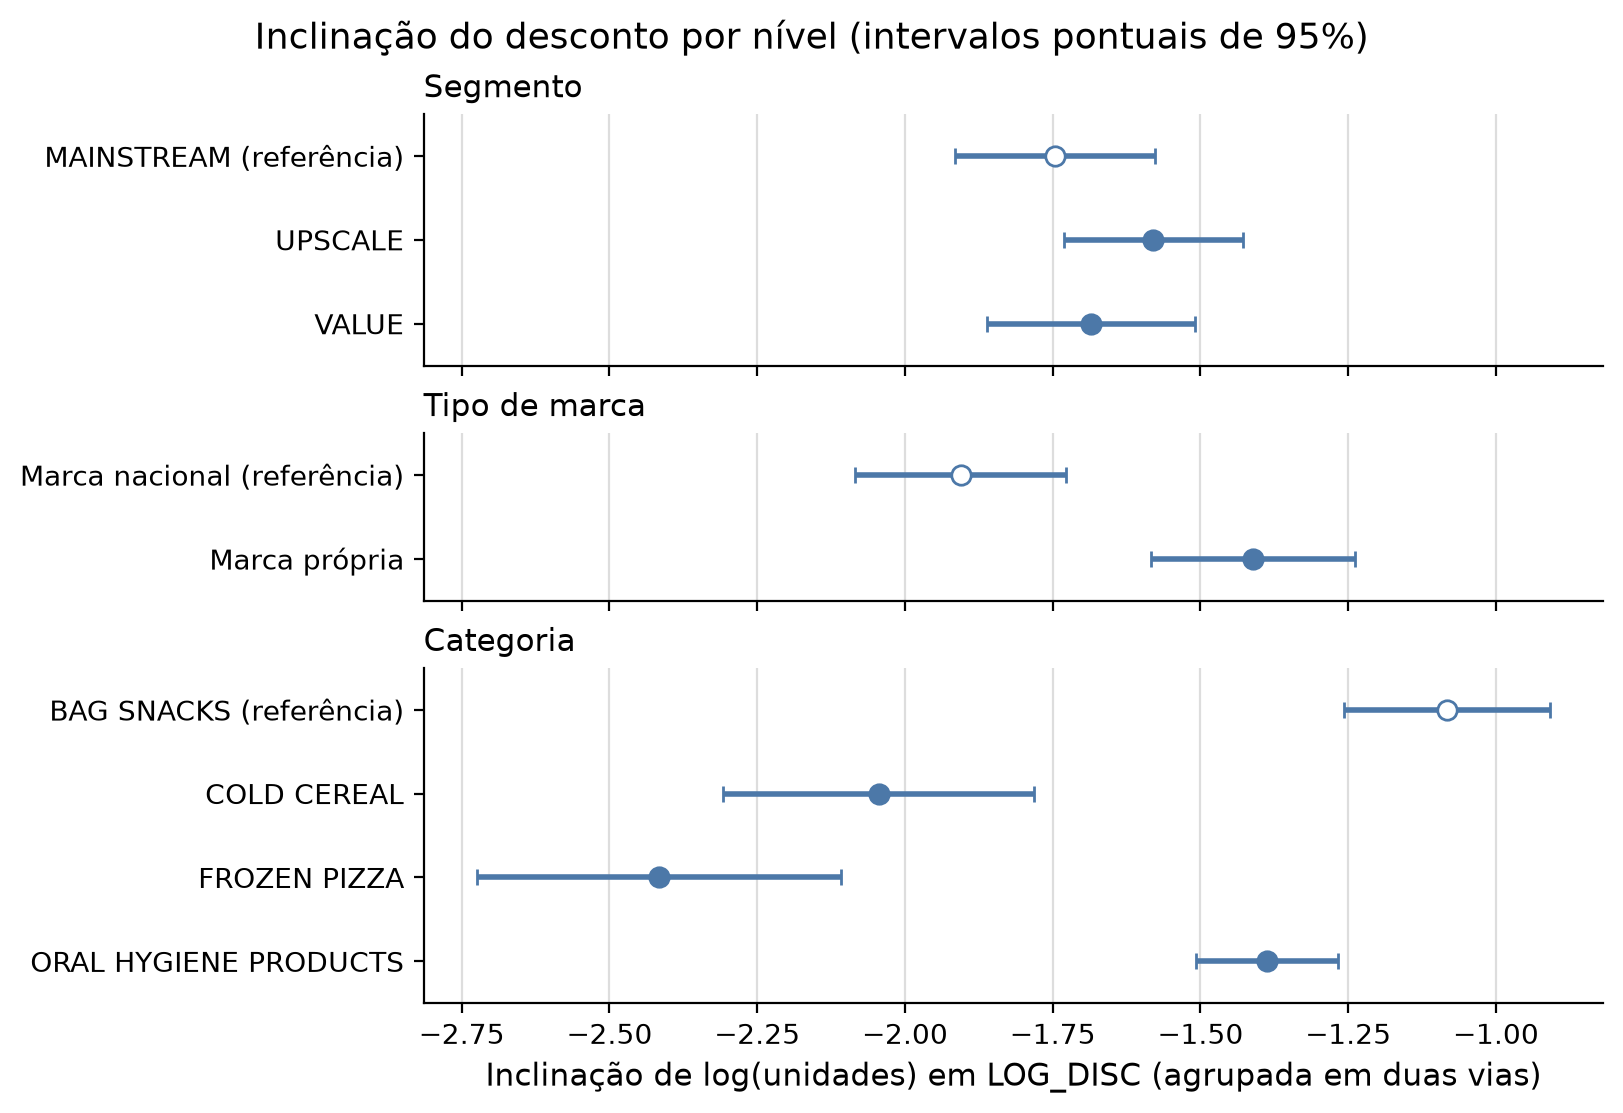

In [9]:
slopes = contrasts.load_table("slopes")
display(localized(slopes.drop(columns=["interval"])))
fig = viz.plot_moderator_slopes(slopes, LANG)

Por segmento, as inclinações são −1,746 (MAINSTREAM, a referência), −1,580 (UPSCALE) e −1,686 (VALUE). A diferença de UPSCALE em relação à referência é de 0,166, com intervalo pontual de 0,072 a 0,261, e a de VALUE é de 0,060, com intervalo de −0,052 a 0,172, que contém zero. Entre as diferenças por nível do segmento, apenas a de UPSCALE tem intervalo pontual que exclui zero. Essa leitura é descritiva, porque o intervalo é pontual e não tem ajuste para multiplicidade. O teste global de segmento indica heterogeneidade no conjunto dos segmentos e, por si só, não identifica qual segmento difere.

Por tipo de marca, a inclinação é de −1,906 para marca de fabricante e de −1,411 para marca própria, uma diferença de 0,494 (intervalo de 0,316 a 0,673): a associação do desconto com as unidades é menos intensa para a marca própria. Por categoria, as inclinações são −1,083 (BAG SNACKS, a referência), −2,044 (COLD CEREAL), −2,416 (FROZEN PIZZA) e −1,387 (ORAL HYGIENE PRODUCTS), com diferenças em relação à referência de −0,961 (intervalo de −1,215 a −0,708), −1,333 (de −1,603 a −1,064) e −0,305 (de −0,458 a −0,152). O desconto está associado a uma resposta maior em pizza congelada e em cereal do que em pretzels.

Esses números descrevem diferenças condicionais de inclinação, e não explicam por que elas ocorrem. Parte delas pode refletir características dos níveis que o modelo não representa, como a distribuição dos descontos praticados (a seção 2 mostrou que o desvio-padrão intrapar do desconto varia entre os níveis) e o calendário promocional. A inclinação comum de `LOG_DISC` no OLS intrapar restrito, de cerca de −1,70, resume essas inclinações nesse estimador, com efeitos fixos de par e de semana e o log do preço-base como controle. Ela não é a inclinação do F3, de −1,685, estimada pelo modelo multinível com interceptos aleatórios, com o preço-base decomposto em desvio e média do par e com tendência e sazonalidade. As duas são próximas, mas vêm de estimadores e controles diferentes, e os cenários do notebook 06 usam a do F3.

## 5. Sensibilidade a choques comuns de categoria × semana

O diagnóstico residual do notebook 03 mostrou que as médias semanais dos resíduos condicionais do F3 variam muito mais do que o esperado sob independência entre linhas, e que a parcela da variância residual associada à combinação de categoria e semana é de 6,4%, contra 0,1% esperado. A questão é se as associações estimadas pelo F3 são sensíveis à representação desses choques comuns. A comparação é, portanto, uma sensibilidade motivada pelo diagnóstico do notebook 03, e não uma troca da especificação oficial.

A referência é o F3 do notebook 03, o C0 do P1, com a parte fixa das decisões D12 a D14 e interceptos aleatórios de loja, produto e par, ajustado por REML com o `lme4` (Bates et al., 2015). A sensibilidade acrescenta `(1 | CATEGORY:WEEK)`, nas mesmas linhas, com a mesma parte fixa e as mesmas médias aprendidas no treino. Um intercepto de categoria × semana representa desvios contemporâneos, comuns a todas as lojas e produtos de uma categoria numa mesma semana. Os efeitos específicos de categoria × semana são condicionais às células já observadas no treino, e não se projetam para semanas futuras. As tabelas a seguir mostram as contagens e a convergência dos dois ajustes.

In [10]:
display(localized(catweek.load_table("counts")).T)
display(localized(catweek.load_table("convergence")))

,0
Linhas,347092
Pares,3859
Lojas,77
Produtos,55
Categorias,4
Níveis de categoria × semana,416
Semanas,104
Última semana,103
Linhas sem categoria,0


,Modelo,Otimizador,Mensagens de convergência,Ajuste singular,Segundos,Parâmetros,Observações,Log-verossimilhança REML,Usado na comparação
0,F3 (referência),bobyqa,,False,69.8190,18,347092,"-274,596.6559",True
1,F3 + categoria × semana,bobyqa,,False,180.4954,19,347092,"-264,270.2786",True


Os dois ajustes usam exatamente as mesmas 347.092 linhas, com 3.859 pares, 77 lojas, 55 produtos, 4 categorias e 416 níveis de categoria × semana (4 categorias em 104 semanas), sem categoria ausente. Ambos convergiram com o otimizador `bobyqa`, sem mensagens de convergência, e nenhum é singular, de modo que não há limitação a registrar e a comparação pode ser lida diretamente. A tabela seguinte compara os efeitos fixos.

,Termo,"Estimativa, F3","EP, F3","Estimativa, com categoria × semana","EP, com categoria × semana",Diferença,Razão dos EP
0,Profundidade do desconto (log preço / base),-1.6852,0.0107,-1.7271,0.0109,-0.0419,1.0177
1,"Preço regular, dentro do par (log)",-1.5921,0.0119,-1.6600,0.0121,-0.0679,1.0191
2,"Preço regular, média do par (log)",-0.8797,0.1054,-0.8840,0.1055,-0.0043,1.0014
3,Encarte,0.4972,0.0043,0.5009,0.0044,0.0036,1.0274
4,Display na loja,0.4087,0.0036,0.4020,0.0035,-0.0067,0.9806
5,Redução temporária de preço (TPR),-0.0412,0.0037,-0.0366,0.0037,0.0046,0.9961
6,Tendência (por ano),-0.0214,0.0018,-0.0249,0.0129,-0.0035,7.3476


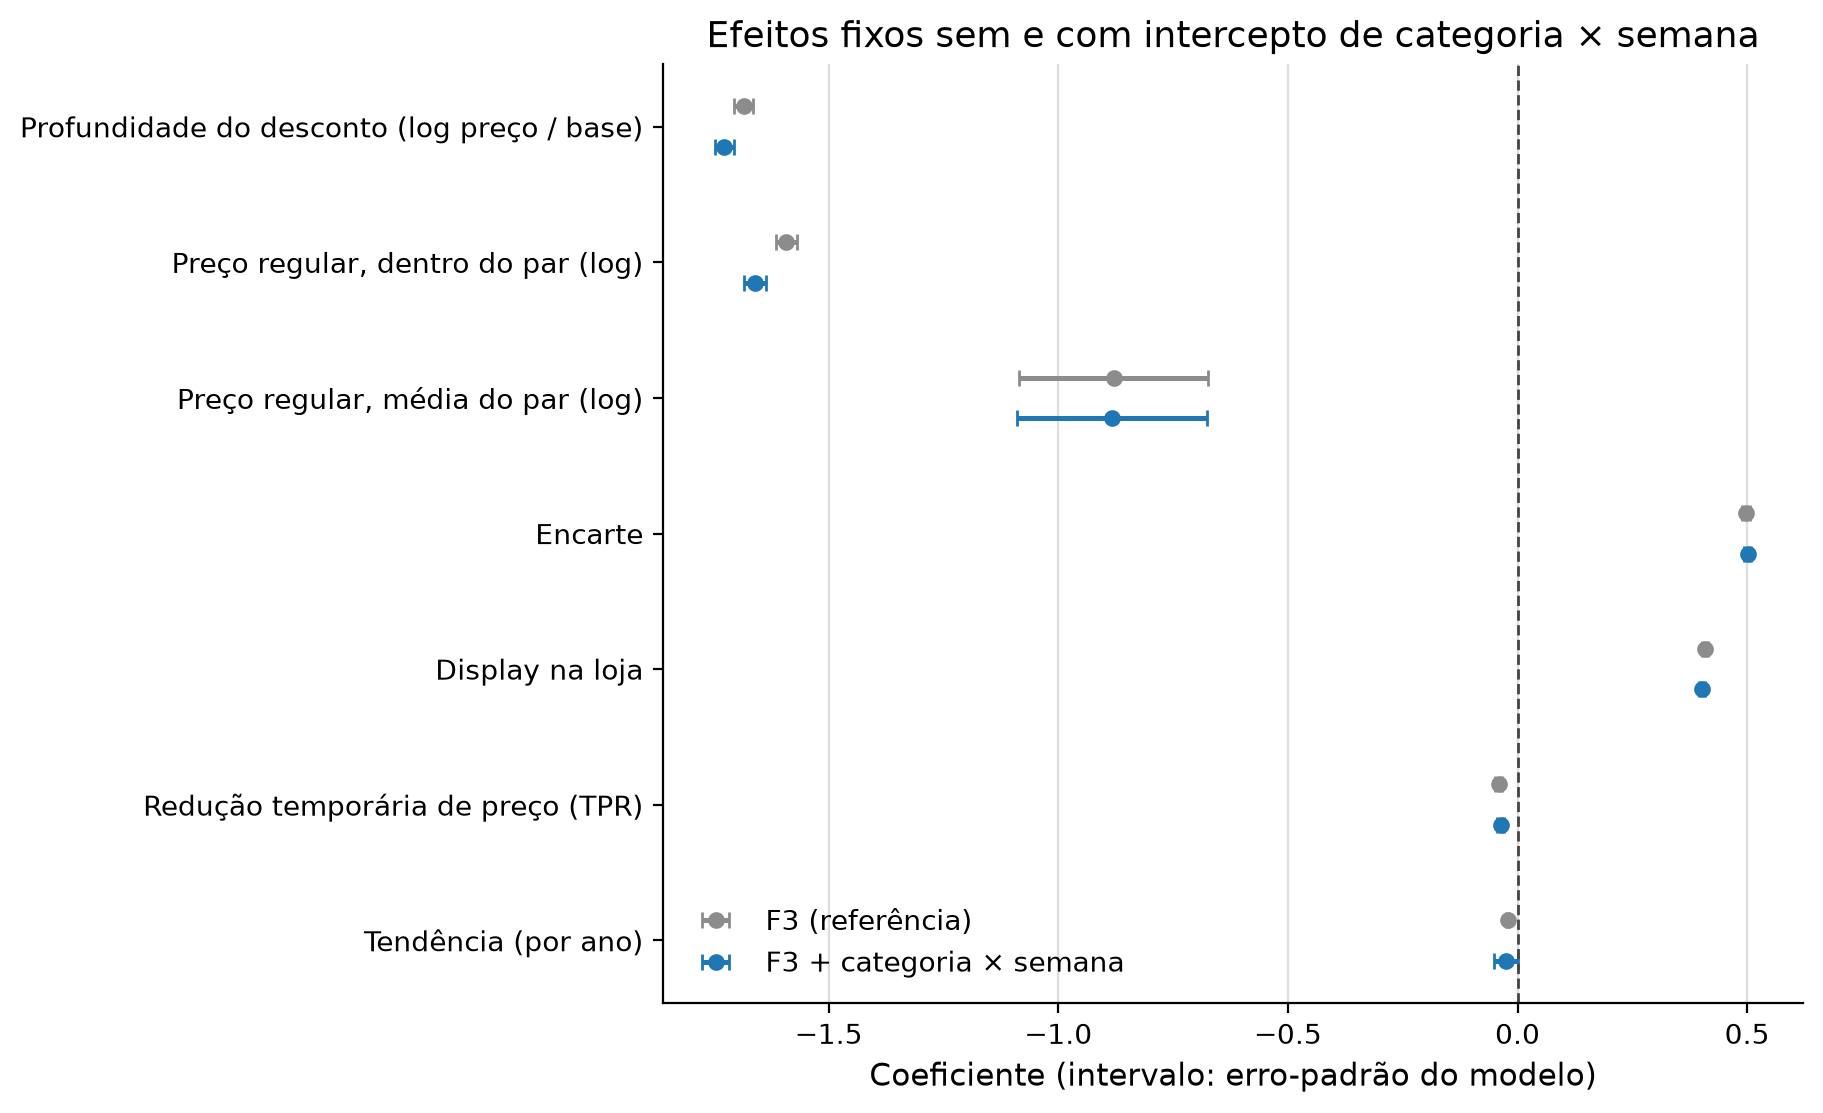

In [11]:
fixef_compare = catweek.load_table("fixef_compare")
display(localized(fixef_compare))
fig = viz.plot_catweek_compare(fixef_compare, LANG)

O coeficiente do desconto passa de −1,685 para −1,727, e o do preço regular dentro do par (`LOG_BASE_DEV`), de −1,592 para −1,660. Os coeficientes de encarte, display e TPR mudam menos de 0,007. O sinal e a ordem de grandeza de todas as associações se mantêm, e as mudanças em desconto e preço regular são de 2,5% e 4,3% do valor de referência. Há uma exceção na precisão: o erro-padrão da tendência (`TREND`) é 7,3 vezes maior, indo de 0,0018 para 0,0129, enquanto os demais ficam entre 0,98 e 1,03 vez os da referência. Como a tendência é uma função apenas da semana, ela é em grande parte representada pelos níveis de categoria × semana, e deixa de ser bem identificada quando eles entram no modelo. Os erros-padrão desta tabela são os do modelo, que o notebook 03 mostrou serem estreitos demais para a inferência completa.

A tabela seguinte mostra as variâncias estimadas dos dois ajustes.

In [12]:
display(localized(catweek.load_table("varcomp")))

,Modelo,Agrupamento,Variância,Desvio-padrão,Participação
0,F3 (referência),Loja × produto,0.1490,0.3861,0.1174
1,F3 (referência),Loja,0.1665,0.4081,0.1312
2,F3 (referência),Produto,0.6815,0.8255,0.5369
3,F3 (referência),Resíduo,0.2724,0.5219,0.2146
4,F3 + categoria × semana,Loja × produto,0.1500,0.3873,0.1182
5,F3 + categoria × semana,Categoria × semana,0.0179,0.1338,0.0141
6,F3 + categoria × semana,Loja,0.1674,0.4091,0.1319
7,F3 + categoria × semana,Produto,0.6789,0.8240,0.5348
8,F3 + categoria × semana,Resíduo,0.2552,0.5052,0.2011


A variância de categoria × semana é de 0,0179 (desvio-padrão de 0,134), o que corresponde a 1,4% da variância total, e a variância residual cai de 0,272 para 0,255. As variâncias de loja, de produto e de par quase não se alteram. A tabela seguinte resume os choques comuns nos resíduos condicionais: a variância das médias semanais, a esperada sob independência, a razão entre elas e a parcela da variância de categoria × semana.

In [13]:
week_summary = catweek.load_table("week_summary")
columns = [
    "model", "var_week_means", "var_expected_independent", "variance_ratio",
    "autocorr_week_means", "share_category_week", "share_category_week_expected",
]  # fmt: skip
with pd.option_context("display.float_format", "{:,.4g}".format):
    display(localized(week_summary[columns]))

,Modelo,Variância dos resíduos médios semanais,Esperada sob independência,Razão frente à independência,Autocorrelação de lag 1 das médias semanais,"Participação da variância, categoria × semana","Participação esperada, categoria × semana"
0,F3 (referência),0.007861,8.088e-05,97.19,-0.004669,0.06363,0.001196
1,F3 + categoria × semana,2.303e-06,7.57e-05,0.03042,0.01947,2.146e-05,0.001196


A razão da variância das médias semanais frente à esperada sob independência cai de 97,2 na referência para 0,03 com o intercepto de categoria × semana, e a parcela de categoria × semana nos resíduos cai de 6,4% para 0,002%. Esse resultado é em parte mecânico, porque os resíduos condicionais são calculados depois de subtrair os efeitos previstos de categoria × semana: ele mostra que o termo absorve os choques comuns contemporâneos, e não que a dependência desapareceu. A autocorrelação de lag 1 das médias semanais dos resíduos já era próxima de zero na referência (−0,005), de modo que não há indício de persistência forte dos choques semanais agregados.

A persistência dentro do par é outra coisa. A tabela e o gráfico seguintes comparam as correlações dos resíduos condicionais do mesmo par em defasagens de calendário de 1 a 4 semanas.

model,F3 (referência),F3 + categoria × semana
Defasagem (semanas),,
1,0.1958,0.1940
2,0.1173,0.1249
3,0.0922,0.1004
4,0.0960,0.0948


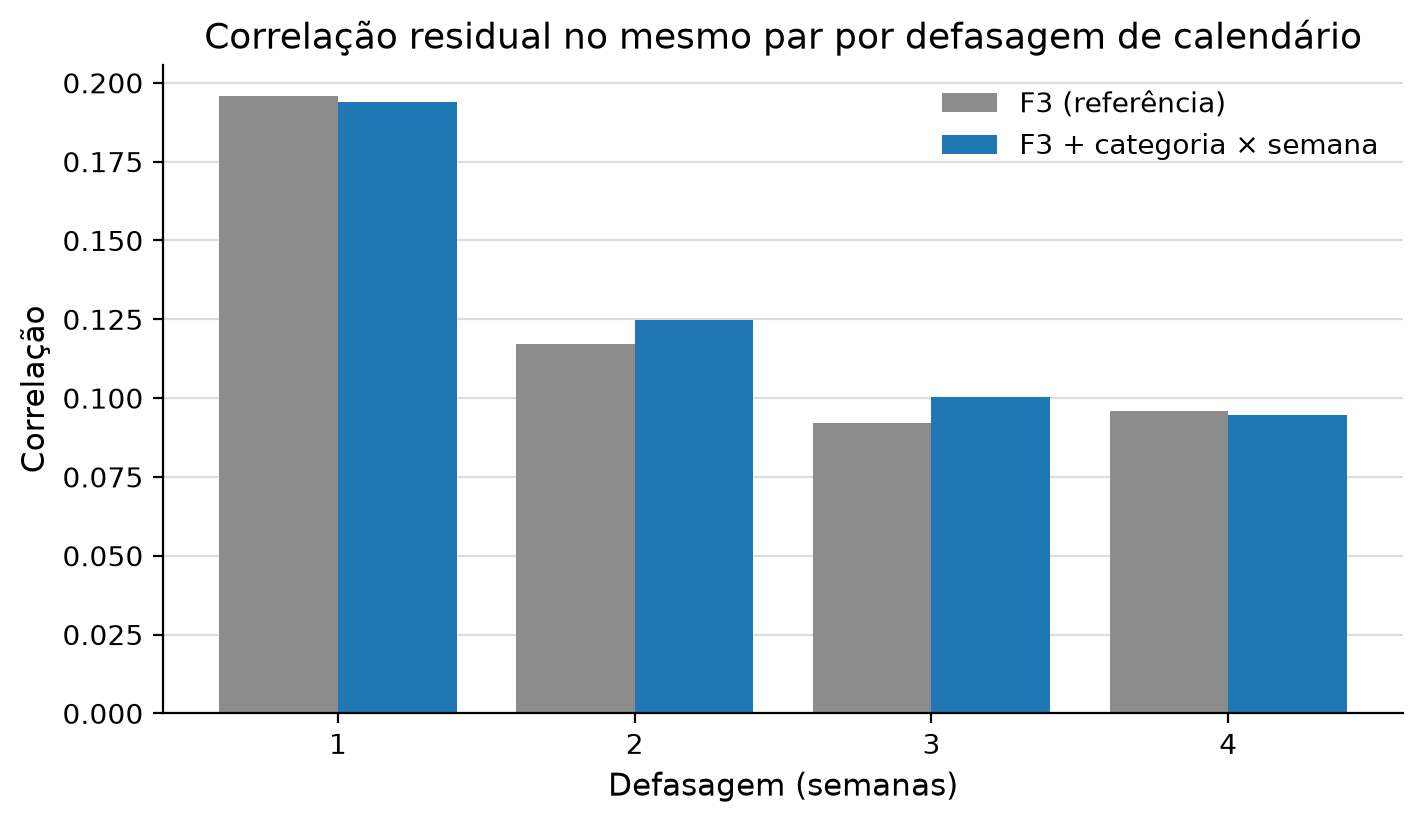

In [14]:
lag_corr = catweek.load_table("lag_corr")
wide = lag_corr.pivot(index="lag", columns="model", values="corr")[list(MODELS)].rename(columns=MODELS)
display(wide.rename_axis(t("f_lag", LANG)))
fig = viz.plot_lag_corr_compare(lag_corr, LANG)

As correlações mudam pouco: na defasagem 1, de 0,196 para 0,194, e nas defasagens de 2 a 4 em no máximo 0,008. A persistência residual dentro do par não é um choque contemporâneo comum a uma categoria, e por isso o termo de categoria × semana não a representa. Nos testes da seção 3, essa persistência é acomodada pelo agrupamento por par, que admite correlação arbitrária entre as semanas de um mesmo par.

Resta registrar a estatística de razão de verossimilhanças entre os dois ajustes REML, que têm a mesma parte fixa. Como se acrescenta uma única variância, o valor-p vem da mistura 50:50 de χ² com 0 e com 1 grau de liberdade (Self & Liang, 1987). O valor-p não é representável em ponto flutuante e é exibido como menor que 1e-300, e não como zero. Dada a dependência remanescente, essa estatística é apenas descritiva, e nenhuma conclusão deste notebook se apoia nela.

In [15]:
lr = catweek.load_json("key_numbers")["lr_descriptive"]
display(
    localize_columns(
        pd.DataFrame([{"stat": lr["stat"], "df": lr["df"], "p_value": format_p(lr["p_value"])}]),
        LANG,
    )
)

,Estatística LR,Graus de liberdade,"Valor-p (mistura 50:50, descritivo)"
0,"20,652.7545",1,< 1e-300


## 6. O que a evidência permite concluir

Nos contrastes, os três testes globais rejeitam a igualdade das inclinações do desconto a 5%, depois da correção de Holm sobre a família fixa de três: por segmento (valor-p ajustado de 0,0031), por tipo de marca (5,51e-07) e por categoria (7,83e-16). Sob a aproximação descrita, isso sustenta que as inclinações não são todas iguais dentro de cada moderador. Não sustenta, por si só, qual nível difere de qual, nem uma explicação para a diferença: as inclinações por nível são descritivas, com intervalos pontuais, e a heterogeneidade descrita é condicional e associativa. A conclusão do segmento é a mais fraca das três e indica heterogeneidade no conjunto dos segmentos. A diferença de UPSCALE, a única com intervalo pontual que exclui zero, é descritiva e não identifica, por si só, o segmento que difere. A inferência é aproximada, porque a dependência entre pares diferentes em semanas diferentes, como choques comuns que persistem de uma semana para outra, não é coberta pelo agrupamento em duas vias.

Na sensibilidade, a introdução de um intercepto aleatório de categoria × semana, que absorve os choques comuns contemporâneos, altera pouco as associações do F3: o desconto e o preço regular dentro do par ficam um pouco mais negativos (de −1,685 para −1,727 e de −1,592 para −1,660), as promoções mudam menos de 0,007, e só a tendência perde precisão. As associações do F3 não se mostram sensíveis, em sinal e em ordem de grandeza, à representação desses choques. Esse resultado não é um teste da especificação oficial, que o C0 e o ranking preditivo do P1 preservam, e a persistência residual dentro do par continua sem tratamento por esse termo.

Os contrastes por nível mostram, enfim, que a inclinação comum do F3 (−1,685) resume associações que, no OLS intrapar, variam de −1,083 a −2,416 entre categorias. Essa informação acompanha a leitura dos cenários do notebook 06, que usa a inclinação comum.

## Referências

Bates, D., Mächler, M., Bolker, B., & Walker, S. (2015). Fitting linear mixed-effects models using lme4. *Journal of Statistical Software, 67*(1), 1–48. https://doi.org/10.18637/jss.v067.i01

Cameron, A. C., & Miller, D. L. (2015). A practitioner's guide to cluster-robust inference. *Journal of Human Resources, 50*(2), 317–372. https://doi.org/10.3368/jhr.50.2.317

Cameron, A. C., Gelbach, J. B., & Miller, D. L. (2011). Robust inference with multiway clustering. *Journal of Business & Economic Statistics, 29*(2), 238–249. https://doi.org/10.1198/jbes.2010.07136

Gelman, A., & Hill, J. (2007). *Data analysis using regression and multilevel/hierarchical models*. Cambridge University Press. https://doi.org/10.1017/CBO9780511790942

Holm, S. (1979). A simple sequentially rejective multiple test procedure. *Scandinavian Journal of Statistics, 6*(2), 65–70. (verificação parcial: fonte não acessível para conferência automática)

Self, S. G., & Liang, K.-Y. (1987). Asymptotic properties of maximum likelihood estimators and likelihood ratio tests under nonstandard conditions. *Journal of the American Statistical Association, 82*(398), 605–610. https://doi.org/10.1080/01621459.1987.10478472

Wooldridge, J. M. (2010). *Econometric analysis of cross section and panel data* (2nd ed.). MIT Press. (verificação parcial: ano da edição não conferido em fonte primária)